In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

df = pd.read_csv("uber.csv")

print(df.head())
print(df.shape)

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [3]:
df.drop(columns=["Unnamed: 0", "key"], inplace=True, errors="ignore")

df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce", utc=True
)

df.dropna(inplace=True)

df["pickup_hour"] = df["pickup_datetime"].dt.hour
df["pickup_day"] = df["pickup_datetime"].dt.day
df["pickup_month"] = df["pickup_datetime"].dt.month
df["pickup_dayofweek"] = df["pickup_datetime"].dt.dayofweek

df.drop(columns=["pickup_datetime"], inplace=True)

df = df[
    (df["fare_amount"] > 0) &
    (df["fare_amount"] <= 100) &
    (df["passenger_count"].between(1, 6)) &
    (df["pickup_latitude"].between(-90, 90)) &
    (df["dropoff_latitude"].between(-90, 90)) &
    (df["pickup_longitude"].between(-180, 180)) &
    (df["dropoff_longitude"].between(-180, 180))
].copy()

print("Dataset after preprocessing:")
print(df.shape)
print(df.head())

Dataset after preprocessing:
(199172, 10)
   fare_amount  pickup_longitude  pickup_latitude  dropoff_longitude  \
0          7.5        -73.999817        40.738354         -73.999512   
1          7.7        -73.994355        40.728225         -73.994710   
2         12.9        -74.005043        40.740770         -73.962565   
3          5.3        -73.976124        40.790844         -73.965316   
4         16.0        -73.925023        40.744085         -73.973082   

   dropoff_latitude  passenger_count  pickup_hour  pickup_day  pickup_month  \
0         40.723217                1           19           7             5   
1         40.750325                1           20          17             7   
2         40.772647                1           21          24             8   
3         40.803349                3            8          26             6   
4         40.761247                5           17          28             8   

   pickup_dayofweek  
0                 3  
1     

Number of outliers: 17036
Lower limit: -3.75
Upper limit: 22.25


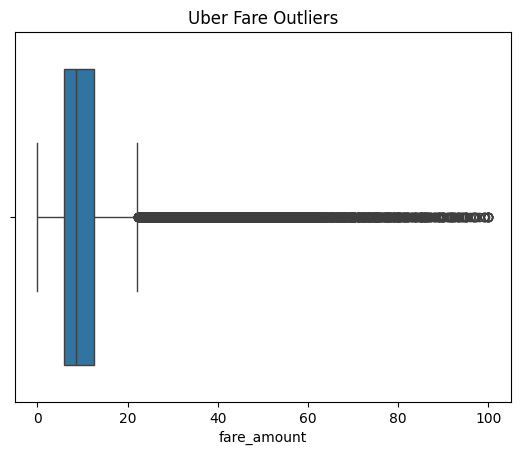

In [4]:
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["fare_amount"] < lower) |
    (df["fare_amount"] > upper)
]

print("Number of outliers:", len(outliers))
print("Lower limit:", lower)
print("Upper limit:", upper)

sns.boxplot(x=df["fare_amount"])
plt.title("Uber Fare Outliers")
plt.show()

In [5]:
df = df[df["fare_amount"].between(lower, upper)].copy()

print("Shape after removing outliers:", df.shape)

Shape after removing outliers: (182136, 10)


In [6]:
def haversine_distance(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return 6371 * 2 * np.arcsin(np.sqrt(a))


df["distance_km"] = haversine_distance(
    df["pickup_latitude"],
    df["pickup_longitude"],
    df["dropoff_latitude"],
    df["dropoff_longitude"]
)

df = df[df["distance_km"] > 0].copy()

print(df[["distance_km", "fare_amount"]].head())

   distance_km  fare_amount
0     1.683323          7.5
1     2.457590          7.7
2     5.036377         12.9
3     1.661683          5.3
4     4.475450         16.0


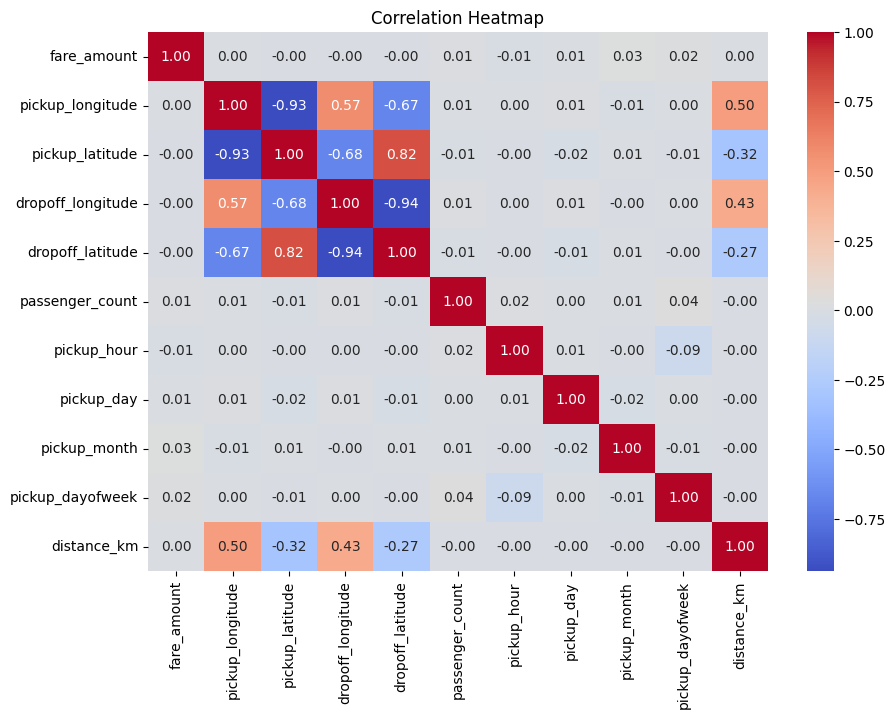

fare_amount          1.000000
pickup_month         0.026640
pickup_dayofweek     0.020355
passenger_count      0.012966
pickup_day           0.006713
distance_km          0.002267
pickup_longitude     0.002106
dropoff_latitude    -0.000148
dropoff_longitude   -0.001294
pickup_latitude     -0.002682
pickup_hour         -0.013137
Name: fare_amount, dtype: float64


In [7]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

print(df.corr(numeric_only=True)["fare_amount"].sort_values(ascending=False))

In [8]:
features = [
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "passenger_count",
    "pickup_hour",
    "pickup_day",
    "pickup_month",
    "pickup_dayofweek",
    "distance_km"
]

X = df[features]
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (141620, 10)
Testing data: (35405, 10)


In [9]:
models = {
    "Linear Regression": make_pipeline(
        StandardScaler(), LinearRegression()
    ),
    "Ridge Regression": make_pipeline(
        StandardScaler(), Ridge(alpha=1.0)
    ),
    "Lasso Regression": make_pipeline(
        StandardScaler(), Lasso(alpha=0.01, max_iter=10000)
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "R2 Score": r2_score(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "MAE": mean_absolute_error(y_test, predictions)
    })

print("All models trained successfully!")

All models trained successfully!


In [10]:
results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

            Model  R2 Score   RMSE    MAE
Linear Regression    0.0013 4.1408 3.2946
 Ridge Regression    0.0013 4.1408 3.2946
 Lasso Regression    0.0013 4.1408 3.2944


In [11]:
sample = X_test.iloc[[0]]

print("Actual Fare:", round(y_test.iloc[0], 2))

for name, model in models.items():
    prediction = model.predict(sample)[0]
    print(name, "Predicted Fare:", round(prediction, 2))

Actual Fare: 5.5
Linear Regression Predicted Fare: 9.42
Ridge Regression Predicted Fare: 9.42
Lasso Regression Predicted Fare: 9.35
